# 圆孔受压：稳健的位移型 PINN 基准

本 notebook 使用传统位移型 PINN 求解无限大平面圆孔受压问题，并与解析解及 BEM 解对比。

本修正版针对“训练损失较低但场结果失真”进行了以下修复：

1. 在孔边外侧采用对数径向加密的 PDE 配点，消除孔边与最近内点之间的无约束环带；
2. 分别计算全域与近孔 PDE 损失，避免近孔平衡残差被大面积远场点稀释；
3. 使用有界的极坐标与远场衰减特征，替代原来线性相关的重复坐标缩放；
4. 通过网络表达严格保持本算例的几何与载荷对称性，但不嵌入解析解；
5. 对位移、应力和 PDE 残差进行一致无量纲化，并避免过大的边界损失权重诱发伪边界层；
6. Adam 阶段周期性重采样，L-BFGS 阶段使用固定点集；
7. 直接使用无限域解析解检查位移、应力、孔边牵引和径向截线。


## 1. 传统 PINN 求解


device=cuda, dtype=torch.float32
=== Pressurized circular hole: displacement-based PINN ===
E*=1000, P0*=1, lambda*=576.923, mu*=384.615, Uref=1.300000e-03 m
trainable parameters: 37922
interior=12000 (global=4000, logarithmic near-hole=8000), hole boundary=720, outer boundary=960
weights: PDE-global=1.0, PDE-near=4.0, hole=10.0, outer=10.0
Start Adam pretraining...
Adam     0 | total=1.400e+01 | PDE-g=6.608e-04 | PDE-n=1.295e+00 | hole=7.984e-01 | outer=8.380e-02
Adam   250 | total=1.747e-02 | PDE-g=2.380e-05 | PDE-n=3.231e-03 | hole=1.523e-04 | outer=3.003e-04
Adam   500 | total=5.844e-03 | PDE-g=9.200e-06 | PDE-n=1.362e-03 | hole=1.368e-05 | outer=2.489e-05
Adam   750 | total=2.625e-03 | PDE-g=5.857e-06 | PDE-n=5.815e-04 | hole=6.824e-06 | outer=2.254e-05
Adam  1000 | total=1.529e-03 | PDE-g=2.156e-06 | PDE-n=3.330e-04 | hole=5.635e-06 | outer=1.382e-05
Adam  1250 | total=1.079e-03 | PDE-g=1.524e-06 | PDE-n=2.429e-04 | hole=7.218e-06 | outer=3.390e-06
Adam  1500 | total=3.967e-04 | 

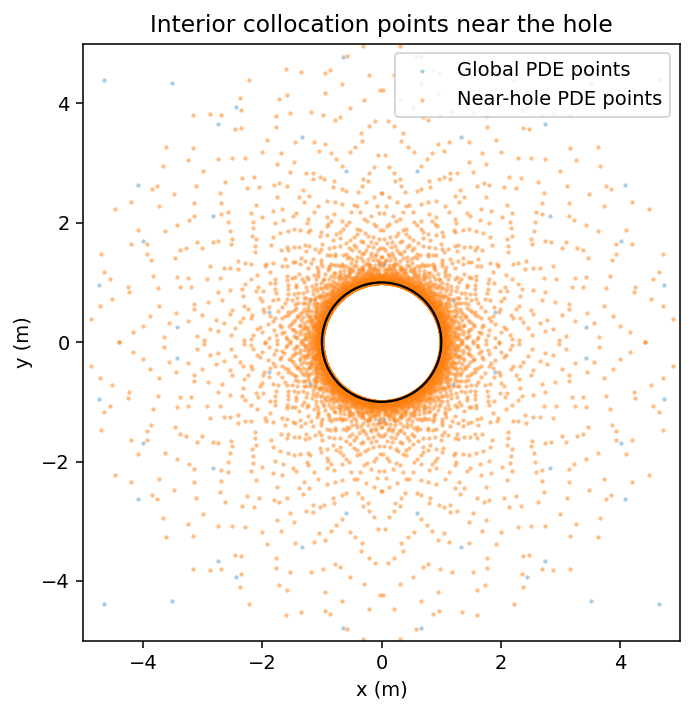

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import time
import random
import os

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"


def seed_everything(seed=1234):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(1234)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 完整训练使用 float32 可显著降低 RTX 4060 上二阶自动微分的耗时。
# 若需要最终高精度复核，可将 USE_DOUBLE 改为 True。
USE_DOUBLE = False
DTYPE = torch.float64 if USE_DOUBLE else torch.float32
torch.set_default_dtype(DTYPE)

print(f"device={device}, dtype={DTYPE}")

# ============================================================
# 1. 物理参数与一致的无量纲尺度
# ============================================================
a = 1.0
P0_real = 1.0e6
E_real = 1.0e9
nu = 0.3
L_out = 80.0 * a
half_L = 0.5 * L_out

STRESS_SCALE = P0_real
P0 = P0_real / STRESS_SCALE
E_PINN = E_real / STRESS_SCALE
LAM_PINN = E_PINN * nu / ((1.0 + nu) * (1.0 - 2.0 * nu))
MU_PINN = E_PINN / (2.0 * (1.0 + nu))
G_PINN = MU_PINN

# 无限域解在孔边的特征位移 P0*a/(2G)。网络输出乘以该尺度后仍为 m。
DISP_SCALE = P0 * a / (2.0 * G_PINN)

print("=== Pressurized circular hole: displacement-based PINN ===")
print(
    f"E*={E_PINN:.6g}, P0*={P0:.6g}, lambda*={LAM_PINN:.6g}, "
    f"mu*={MU_PINN:.6g}, Uref={DISP_SCALE:.6e} m"
)


# ============================================================
# 2. 对称性保持的位移型网络
# ============================================================
class CircularHolePINN(nn.Module):
    """位移型 PINN。

    网络只使用由问题对称性允许的不变量作为幅值输入：rho=a/r、
    cos(2theta)、(x/L)^2、(y/L)^2。最终乘以 cos(theta) 或 sin(theta)，
    从结构上保证 ux 关于 x 为奇函数、关于 y 为偶函数；uy 则相反。
    这里没有加入解析位移或应力，只编码已知的几何/载荷对称性。
    """

    def __init__(self, hidden=96, depth=5):
        super().__init__()
        layers = [nn.Linear(4, hidden), nn.Tanh()]
        for _ in range(depth - 1):
            layers += [nn.Linear(hidden, hidden), nn.Tanh()]
        layers.append(nn.Linear(hidden, 2))
        self.net = nn.Sequential(*layers)
        self._init_weights()

    def _init_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.xavier_uniform_(module.weight)
                nn.init.zeros_(module.bias)

    @staticmethod
    def features(x, y):
        r2 = torch.clamp(x.square() + y.square(), min=(1.0e-12 * a) ** 2)
        r = torch.sqrt(r2)
        c = x / r
        s = y / r
        rho = a / r
        return torch.cat(
            [
                rho,
                c.square() - s.square(),
                (x / half_L).square(),
                (y / half_L).square(),
            ],
            dim=1,
        ), c, s

    def forward(self, x, y):
        feat, c, s = self.features(x, y)
        amplitude = self.net(feat)
        ux = DISP_SCALE * c * amplitude[:, 0:1]
        uy = DISP_SCALE * s * amplitude[:, 1:2]
        return ux, uy


model = CircularHolePINN(hidden=96, depth=5).to(device=device, dtype=DTYPE)
print("trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


def grad(outputs, inputs):
    return torch.autograd.grad(
        outputs,
        inputs,
        grad_outputs=torch.ones_like(outputs),
        create_graph=True,
    )[0]


def analytical_outer_displacement_torch(x, y):
    r2 = torch.clamp(x.square() + y.square(), min=(1.0e-12 * a) ** 2)
    ux = (P0 * a**2 * x) / (2.0 * G_PINN * r2)
    uy = (P0 * a**2 * y) / (2.0 * G_PINN * r2)
    return ux, uy


def compute_pinn_fields(case_model, x, y):
    ux, uy = case_model(x, y)
    ux_x = grad(ux, x)
    ux_y = grad(ux, y)
    uy_x = grad(uy, x)
    uy_y = grad(uy, y)

    sig_xx = (LAM_PINN + 2.0 * MU_PINN) * ux_x + LAM_PINN * uy_y
    sig_yy = (LAM_PINN + 2.0 * MU_PINN) * uy_y + LAM_PINN * ux_x
    sig_xy = MU_PINN * (ux_y + uy_x)
    return ux, uy, sig_xx, sig_yy, sig_xy


def pde_residual(case_model, x, y):
    _, _, sig_xx, sig_yy, sig_xy = compute_pinn_fields(case_model, x, y)
    rx = grad(sig_xx, x) + grad(sig_xy, y)
    ry = grad(sig_xy, x) + grad(sig_yy, y)
    return rx, ry


# ============================================================
# 3. 全域与近孔分层配点
# ============================================================
N_IN_GLOBAL = 4000
N_IN_NEAR = 8000
N_HOLE_BND = 720
N_OUT_BND = 240  # 每条外边界；四条边共 960 点

# 最近 PDE 点与孔边只相差 1e-4*a，避免原代码中 0.02*a 的无约束空白环带。
NEAR_DELTA_MIN = 1.0e-4
NEAR_DELTA_MAX = 4.0

ADAM_EPOCHS = 4000
LBFGS_MAX_ITER = 3500
RESAMPLE_EVERY = 250

# 各项已经无量纲化。近孔 PDE 单独平均并提高权重，防止被远场点稀释。
PDE_GLOBAL_WEIGHT = 1.0
PDE_NEAR_WEIGHT = 4.0
HOLE_TRACTION_WEIGHT = 10.0
OUTER_DISP_WEIGHT = 10.0


def _mirror_quadrant_points(xy_quadrant, n_required):
    x = xy_quadrant[:, 0:1]
    y = xy_quadrant[:, 1:2]
    xy = torch.cat(
        [
            torch.cat([x, y], dim=1),
            torch.cat([-x, y], dim=1),
            torch.cat([x, -y], dim=1),
            torch.cat([-x, -y], dim=1),
        ],
        dim=0,
    )
    return xy[: int(n_required)]


def _draw_global_points(n_points, seed):
    n_quarter = (int(n_points) + 3) // 4
    sobol = torch.quasirandom.SobolEngine(dimension=2, scramble=True, seed=seed)
    chunks = []
    total = 0
    while total < n_quarter:
        uv = sobol.draw(max(2048, 2 * n_quarter), dtype=DTYPE)
        xy = uv * half_L
        r = torch.sqrt(xy[:, 0].square() + xy[:, 1].square())
        valid = xy[r > a * (1.0 + NEAR_DELTA_MIN)]
        chunks.append(valid)
        total += valid.shape[0]
    quadrant = torch.cat(chunks, dim=0)[:n_quarter]
    return _mirror_quadrant_points(quadrant, n_points).to(device)


def _draw_near_hole_points(n_points, seed):
    """在 r-a 上进行对数采样，使 PDE 点真正贴近孔边。"""
    n_quarter = (int(n_points) + 3) // 4
    sobol = torch.quasirandom.SobolEngine(dimension=2, scramble=True, seed=seed)
    uv = sobol.draw(n_quarter, dtype=DTYPE)
    theta = 0.5 * torch.pi * uv[:, 0:1]
    log_delta = (
        np.log(NEAR_DELTA_MIN)
        + uv[:, 1:2] * (np.log(NEAR_DELTA_MAX) - np.log(NEAR_DELTA_MIN))
    )
    r = a * (1.0 + torch.exp(log_delta))
    quadrant = torch.cat([r * torch.cos(theta), r * torch.sin(theta)], dim=1)
    return _mirror_quadrant_points(quadrant, n_points).to(device)


def make_training_points(seed_offset=0):
    xy_global = _draw_global_points(N_IN_GLOBAL, 1234 + int(seed_offset))
    xy_near = _draw_near_hole_points(N_IN_NEAR, 5678 + int(seed_offset))

    theta_hole = torch.linspace(
        0.0,
        2.0 * torch.pi,
        N_HOLE_BND + 1,
        device=device,
        dtype=DTYPE,
    )[:-1].view(-1, 1)

    k = torch.arange(1, N_OUT_BND + 1, device=device, dtype=DTYPE).view(-1, 1)
    t01 = 0.5 * (1.0 - torch.cos(torch.pi * k / (N_OUT_BND + 1)))
    t = -half_L + L_out * t01
    half = torch.full_like(t, half_L)
    outer = {
        "top": (t.clone(), half.clone()),
        "bottom": (t.clone(), -half.clone()),
        "right": (half.clone(), t.clone()),
        "left": (-half.clone(), t.clone()),
    }
    return {
        "xy_global": xy_global,
        "xy_near": xy_near,
        "theta_hole": theta_hole,
        "outer": outer,
    }


TRAINING_POINTS = make_training_points()
print(
    f"interior={N_IN_GLOBAL + N_IN_NEAR} "
    f"(global={N_IN_GLOBAL}, logarithmic near-hole={N_IN_NEAR}), "
    f"hole boundary={N_HOLE_BND}, outer boundary={4 * N_OUT_BND}"
)
print(
    f"weights: PDE-global={PDE_GLOBAL_WEIGHT}, PDE-near={PDE_NEAR_WEIGHT}, "
    f"hole={HOLE_TRACTION_WEIGHT}, outer={OUTER_DISP_WEIGHT}"
)


def _as_grad_tensor(base):
    return base.detach().clone().requires_grad_(True)


def _pde_mse(case_model, xy):
    x = _as_grad_tensor(xy[:, 0:1])
    y = _as_grad_tensor(xy[:, 1:2])
    rx, ry = pde_residual(case_model, x, y)
    return torch.mean((a * rx).square() + (a * ry).square())


def get_total_loss(case_model, training_points):
    loss_pde_global = _pde_mse(case_model, training_points["xy_global"])
    loss_pde_near = _pde_mse(case_model, training_points["xy_near"])

    theta = training_points["theta_hole"]
    x_hole = (a * torch.cos(theta)).detach().clone().requires_grad_(True)
    y_hole = (a * torch.sin(theta)).detach().clone().requires_grad_(True)
    _, _, sig_xx_h, sig_yy_h, sig_xy_h = compute_pinn_fields(
        case_model, x_hole, y_hole
    )

    cos2 = (x_hole.square() - y_hole.square()) / a**2
    sin2 = 2.0 * x_hole * y_hole / a**2
    sig_rr = (
        0.5 * (sig_xx_h + sig_yy_h)
        + 0.5 * (sig_xx_h - sig_yy_h) * cos2
        + sig_xy_h * sin2
    )
    sig_rt = -0.5 * (sig_xx_h - sig_yy_h) * sin2 + sig_xy_h * cos2
    loss_hole = torch.mean(((sig_rr + P0) / P0).square() + (sig_rt / P0).square())

    loss_outer = torch.zeros((), dtype=DTYPE, device=device)
    for x_base, y_base in training_points["outer"].values():
        x = x_base.detach().clone()
        y = y_base.detach().clone()
        ux_pred, uy_pred = case_model(x, y)
        ux_exact, uy_exact = analytical_outer_displacement_torch(x, y)
        loss_outer = loss_outer + torch.mean(
            ((ux_pred - ux_exact) / DISP_SCALE).square()
            + ((uy_pred - uy_exact) / DISP_SCALE).square()
        )
    loss_outer = loss_outer / len(training_points["outer"])

    total_loss = (
        PDE_GLOBAL_WEIGHT * loss_pde_global
        + PDE_NEAR_WEIGHT * loss_pde_near
        + HOLE_TRACTION_WEIGHT * loss_hole
        + OUTER_DISP_WEIGHT * loss_outer
    )
    parts = {
        "pde_global": loss_pde_global,
        "pde_near": loss_pde_near,
        "hole": loss_hole,
        "outer": loss_outer,
    }
    return total_loss, parts


# ============================================================
# 4. Adam（周期重采样）+ L-BFGS（固定点集）
# ============================================================
optimizer = torch.optim.Adam(model.parameters(), lr=8.0e-4)
loss_history = []
t0 = time.time()
print("Start Adam pretraining...")

for epoch in range(ADAM_EPOCHS):
    if epoch > 0 and epoch % RESAMPLE_EVERY == 0:
        TRAINING_POINTS = make_training_points(seed_offset=epoch // RESAMPLE_EVERY)

    optimizer.zero_grad(set_to_none=True)
    loss, parts = get_total_loss(model, TRAINING_POINTS)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=100.0)
    optimizer.step()

    loss_history.append(
        [
            epoch,
            loss.item(),
            parts["pde_global"].item(),
            parts["pde_near"].item(),
            parts["hole"].item(),
            parts["outer"].item(),
        ]
    )
    if epoch % 250 == 0 or epoch == ADAM_EPOCHS - 1:
        print(
            f"Adam {epoch:5d} | total={loss.item():.3e} | "
            f"PDE-g={parts['pde_global'].item():.3e} | "
            f"PDE-n={parts['pde_near'].item():.3e} | "
            f"hole={parts['hole'].item():.3e} | outer={parts['outer'].item():.3e}"
        )

print(f"Adam time: {time.time() - t0:.2f} s")

# L-BFGS 必须使用固定点，不能在 closure 内重采样。
TRAINING_POINTS = make_training_points(seed_offset=999)
lbfgs_optimizer = torch.optim.LBFGS(
    model.parameters(),
    lr=1.0,
    max_iter=LBFGS_MAX_ITER,
    max_eval=2 * LBFGS_MAX_ITER,
    history_size=100,
    tolerance_grad=1.0e-9,
    tolerance_change=1.0e-12,
    line_search_fn="strong_wolfe",
)

lbfgs_eval = {"n": 0}
t1 = time.time()
print("Start L-BFGS refinement...")


def closure():
    lbfgs_optimizer.zero_grad(set_to_none=True)
    loss, parts = get_total_loss(model, TRAINING_POINTS)
    loss.backward()
    lbfgs_eval["n"] += 1
    if lbfgs_eval["n"] % 100 == 0:
        print(
            f"L-BFGS {lbfgs_eval['n']:5d} | total={loss.item():.3e} | "
            f"PDE-g={parts['pde_global'].item():.3e} | "
            f"PDE-n={parts['pde_near'].item():.3e} | "
            f"hole={parts['hole'].item():.3e} | outer={parts['outer'].item():.3e}"
        )
    return loss


lbfgs_optimizer.step(closure)
final_loss, final_parts = get_total_loss(model, TRAINING_POINTS)
PINN_TRAIN_TIME = time.time() - t0
print(
    f"L-BFGS time={time.time() - t1:.2f} s, evaluations={lbfgs_eval['n']}\n"
    f"final total={final_loss.item():.6e}, "
    f"PDE-global={final_parts['pde_global'].item():.6e}, "
    f"PDE-near={final_parts['pde_near'].item():.6e}, "
    f"hole={final_parts['hole'].item():.6e}, "
    f"outer={final_parts['outer'].item():.6e}\n"
    f"total training time={PINN_TRAIN_TIME:.2f} s"
)


# ============================================================
# 5. 批量预测
# ============================================================
def predict_pinn_fields_on_points(case_model, pts, batch_size=10000):
    case_model.eval()
    pts = np.asarray(pts, dtype=np.float64 if DTYPE == torch.float64 else np.float32)
    ux_chunks, uy_chunks = [], []
    sxx_chunks, syy_chunks, sxy_chunks = [], [], []

    for start in range(0, pts.shape[0], int(batch_size)):
        end = min(start + int(batch_size), pts.shape[0])
        batch = pts[start:end]
        x = torch.tensor(batch[:, 0:1], dtype=DTYPE, device=device, requires_grad=True)
        y = torch.tensor(batch[:, 1:2], dtype=DTYPE, device=device, requires_grad=True)
        ux, uy, sig_xx, sig_yy, sig_xy = compute_pinn_fields(case_model, x, y)

        ux_chunks.append(ux.detach().cpu().numpy().reshape(-1))
        uy_chunks.append(uy.detach().cpu().numpy().reshape(-1))
        sxx_chunks.append(sig_xx.detach().cpu().numpy().reshape(-1) * STRESS_SCALE)
        syy_chunks.append(sig_yy.detach().cpu().numpy().reshape(-1) * STRESS_SCALE)
        sxy_chunks.append(sig_xy.detach().cpu().numpy().reshape(-1) * STRESS_SCALE)

    ux_real = np.concatenate(ux_chunks)
    uy_real = np.concatenate(uy_chunks)
    sxx_real = np.concatenate(sxx_chunks)
    syy_real = np.concatenate(syy_chunks)
    sxy_real = np.concatenate(sxy_chunks)
    szz_real = nu * (sxx_real + syy_real)
    vm_real = np.sqrt(
        0.5
        * (
            (sxx_real - syy_real) ** 2
            + (syy_real - szz_real) ** 2
            + (szz_real - sxx_real) ** 2
        )
        + 3.0 * sxy_real**2
    )
    return {
        "ux": ux_real,
        "uy": uy_real,
        "sxx": sxx_real,
        "syy": syy_real,
        "sxy": sxy_real,
        "von_mises": vm_real,
    }


# 查看训练点，确认孔边外侧不存在空白环带。
fig, ax = plt.subplots(figsize=(5.6, 5.2), dpi=140)
xy_g = TRAINING_POINTS["xy_global"].detach().cpu().numpy()
xy_n = TRAINING_POINTS["xy_near"].detach().cpu().numpy()
ax.scatter(xy_g[:, 0], xy_g[:, 1], s=2, alpha=0.25, label="Global PDE points")
ax.scatter(xy_n[:, 0], xy_n[:, 1], s=2, alpha=0.35, label="Near-hole PDE points")
ax.add_patch(plt.Circle((0, 0), a, fill=False, color="black", linewidth=1.2))
ax.set_xlim(-5 * a, 5 * a)
ax.set_ylim(-5 * a, 5 * a)
ax.set_aspect("equal")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.legend(loc="upper right")
ax.set_title("Interior collocation points near the hole")
plt.tight_layout()
plt.show()


## 3. PINN 与解析解/BEM参考解的误差分析

该问题具有无限域解析解。因为解析位移被精确施加在截断方形外边界上，所以解析场也精确满足当前有限计算域的全部边界条件。以下以解析解作为主要误差基准，并保留前面的 BEM 结果作为独立交叉检查。



=== PINN versus analytical solution ===
Relative L2 error Ux        : 3.533245e-02
Relative L2 error Uy        : 3.991823e-02
Relative L2 error von Mises : 8.276866e-03


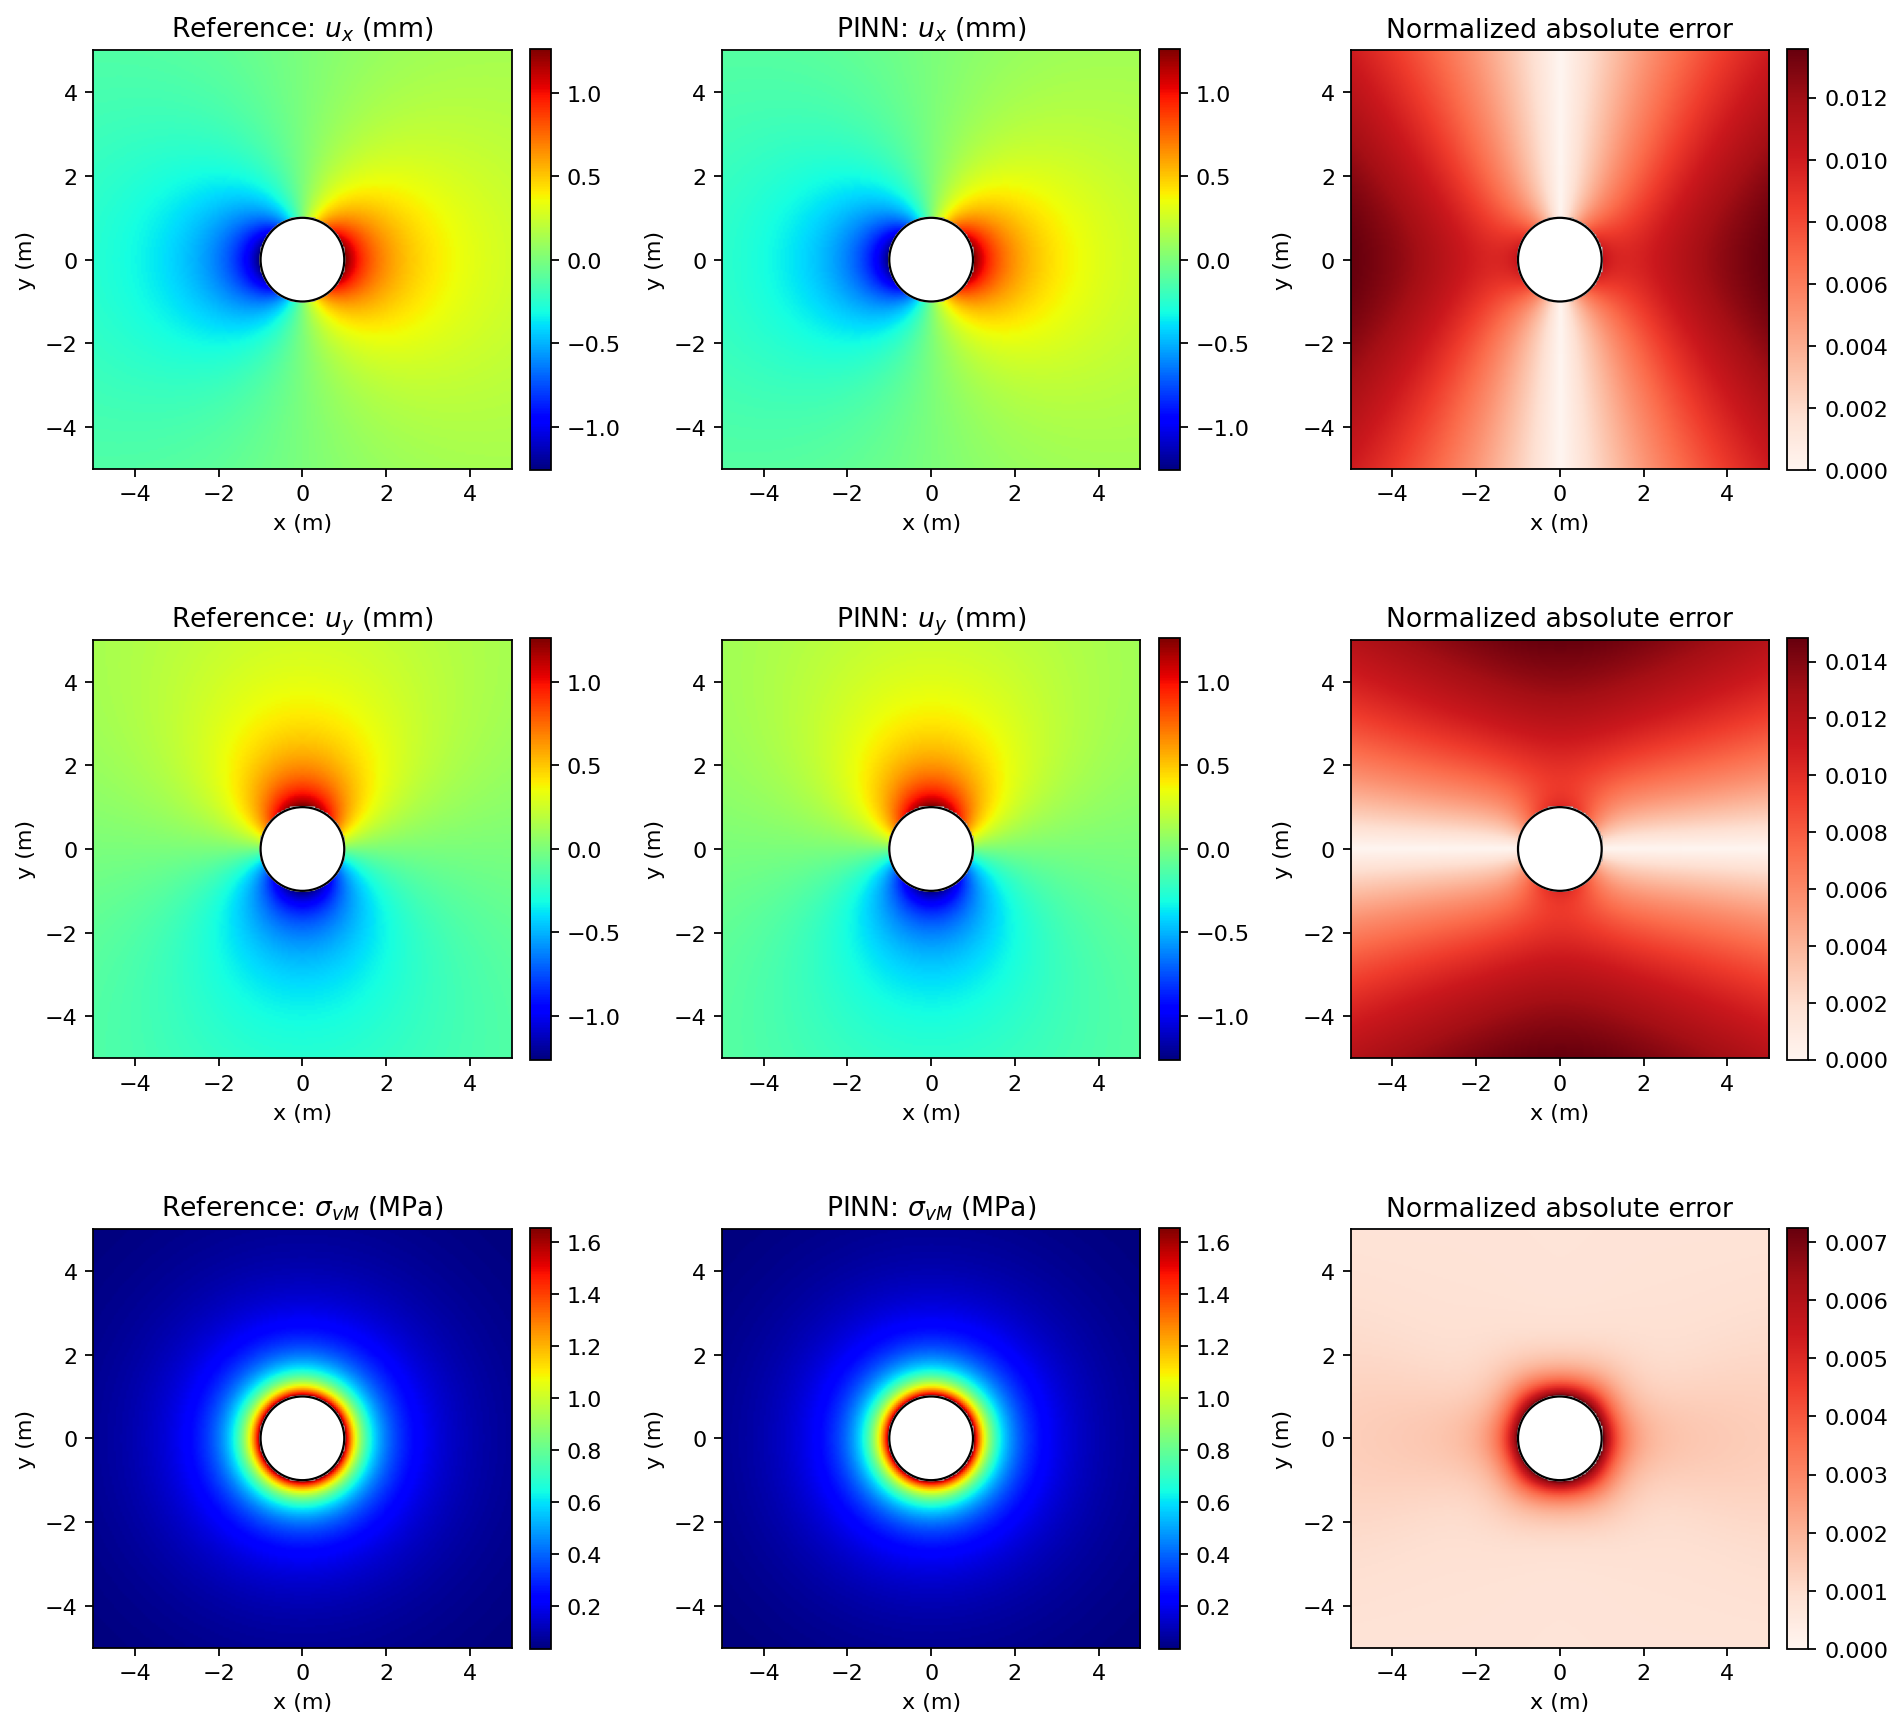

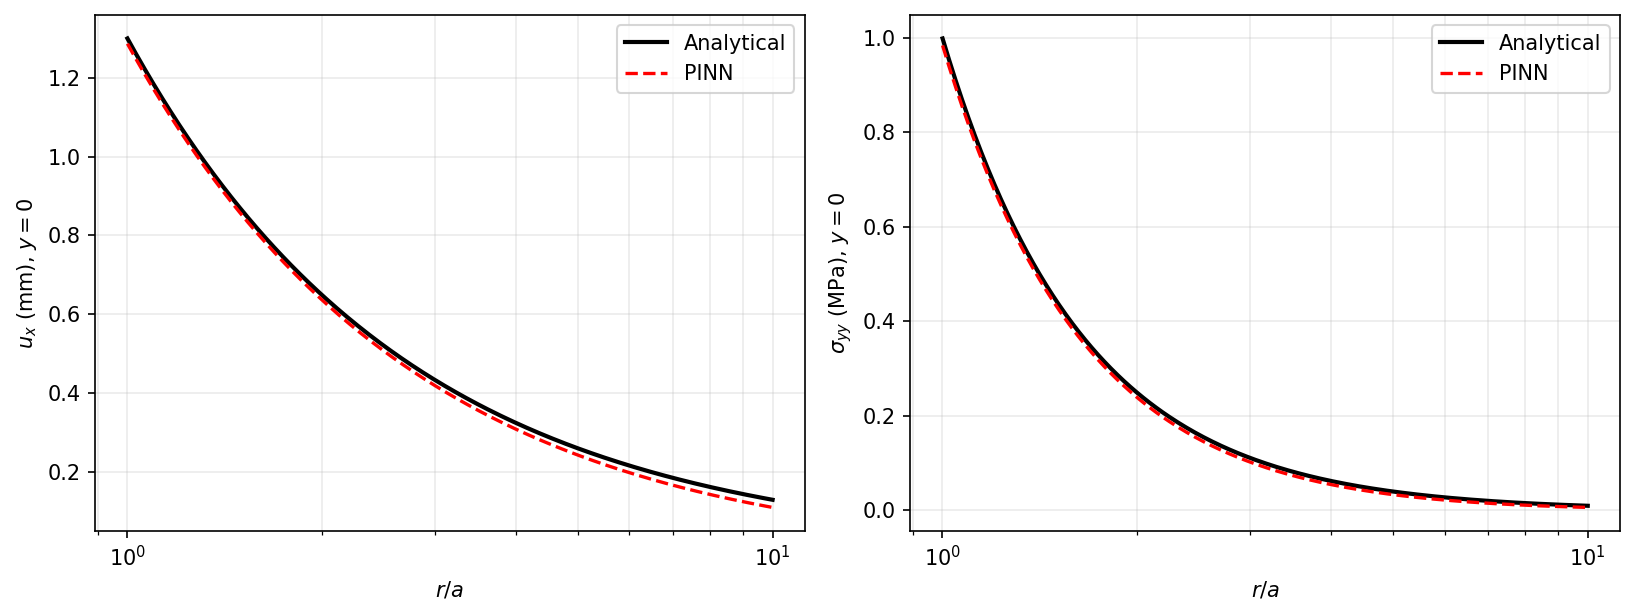

In [3]:
# ============================================================
# 6. 解析解、全场误差和物理诊断
# ============================================================
print("\n=== PINN versus analytical solution ===")


def analytical_fields_numpy(pts):
    pts = np.asarray(pts, dtype=float)
    x = pts[:, 0]
    y = pts[:, 1]
    r2 = np.maximum(x**2 + y**2, (1.0e-12 * a) ** 2)
    r = np.sqrt(r2)
    c = x / r
    s = y / r

    G_real = E_real / (2.0 * (1.0 + nu))
    ux = P0_real * a**2 * x / (2.0 * G_real * r2)
    uy = P0_real * a**2 * y / (2.0 * G_real * r2)

    factor = P0_real * a**2 / r2
    cos2 = c**2 - s**2
    sin2 = 2.0 * c * s
    # sigma_rr=-P0*a^2/r^2, sigma_tt=+P0*a^2/r^2, sigma_rt=0
    sxx = -factor * cos2
    syy = factor * cos2
    sxy = -factor * sin2
    szz = nu * (sxx + syy)
    von_mises = np.sqrt(
        0.5 * ((sxx - syy) ** 2 + (syy - szz) ** 2 + (szz - sxx) ** 2)
        + 3.0 * sxy**2
    )
    return {
        "ux": ux,
        "uy": uy,
        "sxx": sxx,
        "syy": syy,
        "sxy": sxy,
        "von_mises": von_mises,
    }


def relative_l2(pred, ref):
    pred = np.asarray(pred).reshape(-1)
    ref = np.asarray(ref).reshape(-1)
    return float(np.linalg.norm(pred - ref) / max(np.linalg.norm(ref), 1.0e-15))


def normalized_abs_error(pred, ref):
    pred = np.asarray(pred).reshape(-1)
    ref = np.asarray(ref).reshape(-1)
    return np.abs(pred - ref) / max(np.max(np.abs(ref)), 1.0e-15)


# 在论文展示区域 [-5a,5a]^2 上评估，孔边外退 0.02a 与原稿保持一致。
L_plot = 5.0 * a
grid_size = 200
coords_1d = np.linspace(-L_plot, L_plot, grid_size)
XX, YY = np.meshgrid(coords_1d, coords_1d)
pts_all = np.column_stack([XX.ravel(), YY.ravel()])
r_all = np.sqrt(pts_all[:, 0] ** 2 + pts_all[:, 1] ** 2)
valid_mask = r_all > 1.02 * a
eval_pts = pts_all[valid_mask]

pinn_fields = predict_pinn_fields_on_points(model, eval_pts, batch_size=10000)
exact_fields = analytical_fields_numpy(eval_pts)

for key, label in [("ux", "Ux"), ("uy", "Uy"), ("von_mises", "von Mises")]:
    print(f"Relative L2 error {label:10s}: {relative_l2(pinn_fields[key], exact_fields[key]):.6e}")


def field_map(values):
    arr = np.full(grid_size * grid_size, np.nan, dtype=float)
    arr[valid_mask] = np.asarray(values).reshape(-1)
    return arr.reshape(grid_size, grid_size)


PINN_UX_map = field_map(pinn_fields["ux"] * 1.0e3)
PINN_UY_map = field_map(pinn_fields["uy"] * 1.0e3)
PINN_VM_map = field_map(pinn_fields["von_mises"] / 1.0e6)
EXACT_UX_map = field_map(exact_fields["ux"] * 1.0e3)
EXACT_UY_map = field_map(exact_fields["uy"] * 1.0e3)
EXACT_VM_map = field_map(exact_fields["von_mises"] / 1.0e6)

ERR_UX_map = field_map(normalized_abs_error(pinn_fields["ux"], exact_fields["ux"]))
ERR_UY_map = field_map(normalized_abs_error(pinn_fields["uy"], exact_fields["uy"]))
ERR_VM_map = field_map(
    normalized_abs_error(pinn_fields["von_mises"], exact_fields["von_mises"])
)

extent = [-L_plot, L_plot, -L_plot, L_plot]
rows = [
    (EXACT_UX_map, PINN_UX_map, ERR_UX_map, r"$u_x$ (mm)"),
    (EXACT_UY_map, PINN_UY_map, ERR_UY_map, r"$u_y$ (mm)"),
    (EXACT_VM_map, PINN_VM_map, ERR_VM_map, r"$\sigma_{vM}$ (MPa)"),
]

fig, axes = plt.subplots(3, 3, figsize=(12.0, 11.2), dpi=160)
for row, (exact_map, pred_map, err_map, label) in enumerate(rows):
    vmin = float(np.nanmin(exact_map))
    vmax = float(np.nanmax(exact_map))
    maps = [exact_map, pred_map, err_map]
    titles = [f"Reference: {label}", f"PINN: {label}", "Normalized absolute error"]
    for col in range(3):
        ax = axes[row, col]
        if col < 2:
            im = ax.imshow(
                maps[col], origin="lower", extent=extent, cmap="jet", vmin=vmin, vmax=vmax
            )
        else:
            im = ax.imshow(maps[col], origin="lower", extent=extent, cmap="Reds", vmin=0.0)
        ax.add_patch(plt.Circle((0, 0), a, color="white", zorder=3))
        ax.add_patch(plt.Circle((0, 0), a, fill=False, color="black", linewidth=1.0, zorder=4))
        ax.set_aspect("equal")
        ax.set_xlabel("x (m)")
        ax.set_ylabel("y (m)")
        ax.set_title(titles[col])
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


# ============================================================
# 7. 径向截线：判断是否仍存在伪边界层
# ============================================================
r_line = np.geomspace(1.0005 * a, 10.0 * a, 300)
line_pts = np.column_stack([r_line, np.zeros_like(r_line)])
line_pred = predict_pinn_fields_on_points(model, line_pts, batch_size=10000)
line_exact = analytical_fields_numpy(line_pts)

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2), dpi=150)
axes[0].plot(r_line / a, line_exact["ux"] * 1e3, "k-", lw=2, label="Analytical")
axes[0].plot(r_line / a, line_pred["ux"] * 1e3, "r--", lw=1.6, label="PINN")
axes[0].set_xscale("log")
axes[0].set_xlabel(r"$r/a$")
axes[0].set_ylabel(r"$u_x$ (mm), $y=0$")
axes[0].grid(True, which="both", alpha=0.25)
axes[0].legend()

axes[1].plot(r_line / a, line_exact["syy"] / 1e6, "k-", lw=2, label="Analytical")
axes[1].plot(r_line / a, line_pred["syy"] / 1e6, "r--", lw=1.6, label="PINN")
axes[1].set_xscale("log")
axes[1].set_xlabel(r"$r/a$")
axes[1].set_ylabel(r"$\sigma_{yy}$ (MPa), $y=0$")
axes[1].grid(True, which="both", alpha=0.25)
axes[1].legend()
plt.tight_layout()
plt.show()


# 可选：若已运行 BEM 单元，再输出 PINN 相对于 BEM 的误差作为交叉检查。
if all(name in globals() for name in ["internal_pts", "u_int", "von_mises"]):
    bem_pred = predict_pinn_fields_on_points(model, internal_pts, batch_size=10000)
    print("\nOptional PINN versus BEM cross-check:")
    print(f"Ux:        {relative_l2(bem_pred['ux'], np.asarray(u_int)[:, 0]):.6e}")
    print(f"Uy:        {relative_l2(bem_pred['uy'], np.asarray(u_int)[:, 1]):.6e}")
    print(f"von Mises: {relative_l2(bem_pred['von_mises'], np.asarray(von_mises)):.6e}")


## Export PINN full-field data for the 3 x 3 comparison figure

Run this cell after completing the PINN training and prediction cells above. The exported file follows the same grid, variable names, and SI units as `bem_fields.npz`, allowing both files to be loaded directly by the comparison-figure notebook.


In [4]:
# ============================================================
# 8. Export PINN fields for the unified 3 x 3 comparison figure
# ============================================================
from pathlib import Path
import numpy as np

required_variables = [
    "XX", "YY", "grid_size", "valid_mask", "a", "L_plot", "pinn_fields"
]
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise NameError(
        "Please run the PINN training and full-field prediction cells first. "
        "Missing variables: " + ", ".join(missing_variables)
    )

required_field_keys = ["ux", "uy", "sxx", "syy", "sxy", "von_mises"]
missing_field_keys = [key for key in required_field_keys if key not in pinn_fields]
if missing_field_keys:
    raise KeyError(
        "pinn_fields is missing: " + ", ".join(missing_field_keys)
    )

grid_shape = (int(grid_size), int(grid_size))
expected_size = int(grid_size) * int(grid_size)
valid_mask_export = np.asarray(valid_mask, dtype=bool).reshape(-1)

if valid_mask_export.size != expected_size:
    raise ValueError(
        f"valid_mask has {valid_mask_export.size} entries, "
        f"but the grid requires {expected_size}."
    )


def _map_pinn_values(values, name):
    """Map values at exterior evaluation points back to the common full grid."""
    values = np.asarray(values, dtype=float).reshape(-1)
    n_valid = int(np.count_nonzero(valid_mask_export))
    if values.size != n_valid:
        raise ValueError(
            f"pinn_fields['{name}'] has {values.size} entries, "
            f"but valid_mask contains {n_valid} exterior points."
        )
    full = np.full(expected_size, np.nan, dtype=float)
    full[valid_mask_export] = values
    return full.reshape(grid_shape)


# predict_pinn_fields_on_points already returns displacements in m and stresses in Pa.
ux_map_si = _map_pinn_values(pinn_fields["ux"], "ux")
uy_map_si = _map_pinn_values(pinn_fields["uy"], "uy")
sxx_map_si = _map_pinn_values(pinn_fields["sxx"], "sxx")
syy_map_si = _map_pinn_values(pinn_fields["syy"], "syy")
sxy_map_si = _map_pinn_values(pinn_fields["sxy"], "sxy")
vm_map_si = _map_pinn_values(pinn_fields["von_mises"], "von_mises")

X_export = np.asarray(XX, dtype=float)
Y_export = np.asarray(YY, dtype=float)
if X_export.shape != grid_shape or Y_export.shape != grid_shape:
    raise ValueError(
        f"XX/YY shapes must be {grid_shape}; got {X_export.shape} and {Y_export.shape}."
    )

trainable_parameters = (
    int(sum(p.numel() for p in model.parameters() if p.requires_grad))
    if "model" in globals()
    else -1
)
training_time = float(PINN_TRAIN_TIME) if "PINN_TRAIN_TIME" in globals() else np.nan

result_dir = Path.cwd() / "field_results"
result_dir.mkdir(parents=True, exist_ok=True)
output_file = result_dir / "pinn_fields.npz"

np.savez_compressed(
    output_file,
    X=X_export,
    Y=Y_export,
    valid_mask=valid_mask_export.reshape(grid_shape),
    ux=ux_map_si,       # m
    uy=uy_map_si,       # m
    sxx=sxx_map_si,     # Pa
    syy=syy_map_si,     # Pa
    sxy=sxy_map_si,     # Pa
    vm=vm_map_si,       # Pa
    a=float(a),
    L_plot=float(L_plot),
    grid_size=int(grid_size),
    displacement_unit="m",
    stress_unit="Pa",
    method="PINN",
    trainable_parameters=trainable_parameters,
    training_time_s=training_time,
)

# Read the file back immediately and verify compatibility-critical fields.
with np.load(output_file) as check:
    for key in ["X", "Y", "ux", "uy", "sxx", "syy", "sxy", "vm"]:
        if check[key].shape != grid_shape:
            raise RuntimeError(
                f"Export validation failed: {key} has shape {check[key].shape}."
            )
    if check["displacement_unit"].item() != "m":
        raise RuntimeError("Unexpected displacement unit in exported file.")
    if check["stress_unit"].item() != "Pa":
        raise RuntimeError("Unexpected stress unit in exported file.")

print(f"PINN field data saved successfully:\n{output_file.resolve()}")
print(f"Grid: {grid_size} x {grid_size}; exterior points: {valid_mask_export.sum()}")
print(f"Trainable parameters: {trainable_parameters}")
if np.isfinite(training_time):
    print(f"Training time: {training_time:.2f} s")
print(
    "Finite ranges (SI units):\n"
    f"  ux: [{np.nanmin(ux_map_si):.6e}, {np.nanmax(ux_map_si):.6e}] m\n"
    f"  uy: [{np.nanmin(uy_map_si):.6e}, {np.nanmax(uy_map_si):.6e}] m\n"
    f"  vm: [{np.nanmin(vm_map_si):.6e}, {np.nanmax(vm_map_si):.6e}] Pa"
)


PINN field data saved successfully:
C:\Users\magic\Desktop\KM-PIKFNN\圆孔受压\field_results\pinn_fields.npz
Grid: 200 x 200; exterior points: 38712
Trainable parameters: 37922
Training time: 397.72 s
Finite ranges (SI units):
  ux: [-1.248122e-03, 1.248122e-03] m
  uy: [-1.248382e-03, 1.248382e-03] m
  vm: [3.338120e+04, 1.642956e+06] Pa
